In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from keras.layers import Dense, SimpleRNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler

2024-04-13 17:06:07.346363: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-13 17:06:07.489208: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/kaan/summer_ws/devel/lib:/home/kaan/rob_ws/devel/lib:/home/kaan/aria_ws/devel/lib:/home/kaan/catkin_ws/devel/lib:/opt/ros/noetic/lib:/opt/ros/noetic/lib/x86_64-linux-gnu:/home/kaan/.local/lib/python3.9/site-packages/nvidia/cudnn/lib:/usr/local/cuda-12/lib64
2024-04-13 17:06:07.489228: I tensorflow/compiler/xla/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do n

In [2]:
df = pd.read_csv('gazebo_full+_dataset_synced.csv')

In [3]:
y = df.iloc[:,4:]
y

,theta0,theta1,theta2,theta3,theta4,theta5,theta6
0,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
1,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
2,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
3,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
4,2.304645,-0.183875,0.716803,0.958525,0.333288,-0.630830,2.172913
...,...,...,...,...,...,...,...
95865,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95866,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95867,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176
95868,2.339138,-0.149693,-1.162786,1.342337,-1.004323,-0.400514,-0.414176


In [4]:
X = df.iloc[:,1:4]
X

,x,y,z
0,0.479692,-0.115205,0.905620
1,0.479692,-0.115205,0.905620
2,0.479692,-0.115205,0.905620
3,0.479692,-0.115205,0.905620
4,0.479692,-0.115205,0.905620
...,...,...,...
95865,-0.154206,-0.471443,0.801403
95866,-0.154157,-0.471496,0.801452
95867,-0.154109,-0.471548,0.801501
95868,-0.154060,-0.471601,0.801549


In [5]:
X.shape

(95870, 3)

In [6]:
xscaler = MinMaxScaler()
yscaler = MinMaxScaler()
X_s = xscaler.fit_transform(X)
y_s = yscaler.fit_transform(y)

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

In [8]:
# Reshape input to be 3D [samples, timesteps, features]
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

In [9]:
X_train.shape

(76696, 1, 3)

In [14]:
from keras.optimizers import SGD

model = Sequential([
    LSTM(128, activation='relu', input_shape=(1,3)),
    Dense(128, activation='relu'),
    Dense(32, activation='relu'),
    Dense(y_train.shape[1])
])

model.compile(optimizer=SGD(learning_rate=0.01, momentum=0.9), loss='mean_squared_error')

history = model.fit(X_train, y_train, epochs=60, verbose=1)

Epoch 1/60
2397/2397 [==============================] - 7s 2ms/step - loss: 0.0460
Epoch 2/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0432
Epoch 3/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0425
Epoch 4/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0420
Epoch 5/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0413
Epoch 6/60
2397/2397 [==============================] - 6s 3ms/step - loss: 0.0403
Epoch 7/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0386
Epoch 8/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0366
Epoch 9/60
2397/2397 [==============================] - 5s 2ms/step - loss: 0.0352
Epoch 10/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0342
Epoch 11/60
2397/2397 [==============================] - 6s 2ms/step - loss: 0.0335
Epoch 12/60
2397/2397 [==============================] - 5s 2ms/step - loss: 0.0331
E

In [15]:
# Evaluate your model
loss = model.evaluate(X_test, y_test, verbose=0)
print('Test loss:', loss)

Test loss: 0.018185103312134743


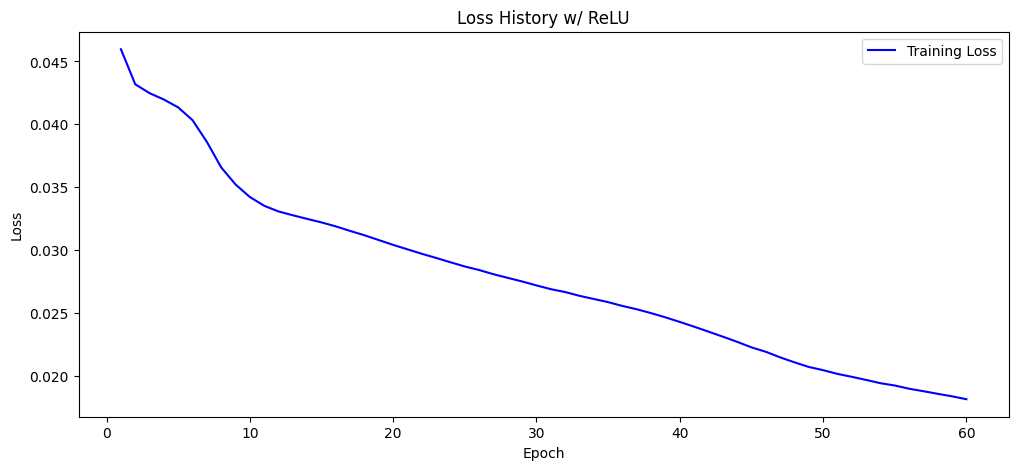

In [51]:
import matplotlib.pyplot as plt

# Get training history
training_loss = history.history['loss']

epoch_count = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(12, 5))
plt.plot(epoch_count, training_loss, 'b-')
plt.legend(['Training Loss', 'Validation Loss'])
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss History w/ ReLU')
plt.show()

In [43]:
# Use your model to predict joint angles from x, y, z coordinates
x_new = np.array([[0.5, 0, 0.4]])  # New x, y, z coordinates
x_new = xscaler.transform(x_new)  # Normalize
x_new = x_new.reshape((1, 1, 3))  # Reshape
y_new = model.predict(x_new)  # Predict
print('Predicted joint angles:', y_new)

/home/kaan/.local/lib/python3.8/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


1/1 [==============================] - 0s 176ms/step
Predicted joint angles: [[0.8157475  0.7729333  0.8378533  0.13116439 0.16878167 0.9498668
  0.8191148 ]]


In [44]:
np.rad2deg(yscaler.inverse_transform(y_new))

array([[ 104.72422  ,   57.956978 ,   61.506313 ,   41.514194 ,
        -111.78303  ,    5.3083577,  -31.438908 ]], dtype=float32)

-
-
-